# Coding Test #2

Problem #2 is using customers-2000000.csv has 2.000.000 rows. Because of its large rows, I need to chunk this data. Then, I'll analyze all of its columns like Coding Test #1

In [1]:
import time
import tracemalloc
from contextlib import contextmanager
import numpy as np
import pandas as pd

PATH = r"D:\personal-project\food-online-test\data\customers-2000000.csv"
CHUNK_SIZE = 50_000          

# Function to read chunks, I create it as a function to makes it possible to be used on another function
def read_chunks(columns=None):
    return pd.read_csv(PATH, usecols=columns, chunksize=CHUNK_SIZE)

# Merge the counts of one chunk into running total
def add_counts(total, part):
    return part if total is None else total.add(part, fill_value=0)

# List to save every measurement, it will be saved as csv at the end for question number 3
results = []

# Function to measure the time & peak memory of the code inside the "with" block
# tracemalloc makes pandas slower, so use memory=False to get the real time
@contextmanager
def track(label, memory=True):
    if memory:
        tracemalloc.start()
    start_time = time.time()
    yield
    end_duration = time.time() - start_time

    peak_mb = None
    if memory:
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_mb = round(peak / 1e6, 1)

    results.append({"label": label, "peak_mb": peak_mb, "time_s": round(end_duration, 2)})
    print(f"[{label}] peak memory: {peak_mb} MB | time: {round(end_duration, 2)} seconds")

In [2]:
# Load the whole file at once (same as coding-1), only to compare it with the chunk method
# First only for the time, second for the peak memory
with track("read csv (time only)", memory=False):
    df = pd.read_csv(PATH)
del df

with track("read csv"):
    df = pd.read_csv(PATH)

print("------------------------")
print("Data Shape (row, column): ", df.shape)
print("DataFrame size after loading: ", round(df.memory_usage(deep=True).sum() / 1e6, 1), "MB")

# Delete it, so the rest of this notebook really uses low memory
del df

[read csv (time only)] peak memory: None MB | time: 11.27 seconds


[read csv] peak memory: 1083.2 MB | time: 21.14 seconds
------------------------
Data Shape (row, column):  (2000000, 12)


DataFrame size after loading:  1403.2 MB


You can see that when we used 100.000 data, it only needs around 0.5 seconds and 55 MB of memory to load it. But with 2.000.000 data, it needs around 11 seconds and the memory peaked at around 1.083 MB (the DataFrame itself is 1.403 MB). Because of that, I don't keep this DataFrame and I chunk the data for the rest of this notebook.

In [3]:
with track("overview"):
    n_rows = 0
    missing = None
    full_load_bytes = 0
    row_hashes = []
    for chunk in read_chunks():
        n_rows += len(chunk)
        missing = add_counts(missing, chunk.isna().sum())
        full_load_bytes += chunk.memory_usage(deep=True).sum()
        row_hashes.append(pd.util.hash_pandas_object(chunk, index=False).to_numpy())
    columns = list(chunk.columns)
    dtypes = chunk.dtypes
    duplicate_rows = n_rows - np.unique(np.concatenate(row_hashes)).size
    del row_hashes, chunk

print("------------------------")
print("Data Shape (rows, columns): ", (n_rows, len(columns)))
print("Memory needed to load everything at once:", round(full_load_bytes / 1e6, 1), "MB")
print("Duplicate rows:", duplicate_rows)
print("------------------------")
display(dtypes)

[overview] peak memory: 88.7 MB | time: 129.0 seconds
------------------------
Data Shape (rows, columns):  (2000000, 12)
Memory needed to load everything at once: 1403.2 MB
Duplicate rows: 0
------------------------


Index                 int64
Customer Id          object
First Name           object
Last Name            object
Company              object
City                 object
Country              object
Phone 1              object
Phone 2              object
Email                object
Subscription Date    object
Website              object
dtype: object

From the data above we can see that the file really has 2.000.000 rows and 12 columns, with no duplicate rows. Loading it at once would need 1.403 MB of memory, while this pass peaked at about 89 MB, because only one chunk of 50.000 rows (plus 8 bytes per row for the hashes) is in memory at a time.

In [4]:
# Read the whole file in chunks without doing anything, to know how long the reading itself takes
# First only for the time (tracemalloc makes it slower), second for the peak memory
with track("read csv in chunks (time only)", memory=False):
    n = 0
    for chunk in read_chunks():
        n += len(chunk)

with track("read csv in chunks"):
    n = 0
    for chunk in read_chunks():
        n += len(chunk)

# Same as the "Country" section below, but without tracemalloc
with track("country (time only)", memory=False):
    country_check = None
    for chunk in read_chunks(["Country"]):
        country_check = add_counts(country_check, chunk["Country"].value_counts())

del chunk

[read csv in chunks (time only)] peak memory: None MB | time: 10.03 seconds


[read csv in chunks] peak memory: 50.9 MB | time: 23.06 seconds


[country (time only)] peak memory: None MB | time: 3.36 seconds


Reading the whole file in chunks only takes around 10 seconds, almost the same as loading it at once (11 seconds), but the memory peaked at only 51 MB instead of 1.083 MB. So chunking itself does not make the process slower. The other sections are slower because every section reads the file again and processes every chunk one by one.

## Data Quality

'unique_count' function will create new unique data as a 8-byte hash, that means everytime it found the same value (duplicates), it will just drop it because it already has its data. This method creates a lower memory while we process the data

In [5]:
# Function to count the unique values of one column, using hashes instead of the values
def unique_count(column):
    seen = np.array([], dtype=np.uint64)
    for chunk in read_chunks([column]):
        hashes = pd.util.hash_pandas_object(chunk[column], index=False).to_numpy()
        seen = np.unique(np.concatenate([seen, hashes]))
    return seen.size


with track("data quality"):
    unique_values = pd.Series({col: unique_count(col) for col in columns})

quality = pd.DataFrame({
    "missing": missing.astype(int),
    "unique_values": unique_values,
    "unique_ratio_pct": (unique_values / n_rows * 100).round(2),
}).sort_values("unique_ratio_pct", ascending=False)
print("------------------------")
display(quality)
print("------------------------")
print("Duplicate rows       :", duplicate_rows)
print("Duplicate Customer Id:", n_rows - unique_values["Customer Id"])

[data quality] peak memory: 69.9 MB | time: 97.25 seconds
------------------------


,missing,unique_values,unique_ratio_pct
Index,0,2000000,100.00
Customer Id,0,2000000,100.00
Phone 2,0,1999993,100.00
Phone 1,0,1999989,100.00
Email,0,1998750,99.94
Company,0,1158713,57.94
Website,0,665324,33.27
City,0,119928,6.00
Last Name,0,1000,0.05
Subscription Date,0,881,0.04


------------------------
Duplicate rows       : 0
Duplicate Customer Id: 0


There are no missing values, no duplicate rows and no duplicate Customer IDs, so the data is complete. Compared with the 100k file, a few values now repeat: Email has 1,998,750 unique values (99.94%), and Phone 1 / Phone 2 have 11 and 7 repeated numbers. Company (57.94%), Website (33.27%) and City (6.00%) are much less unique than in the 100k file, because the generator reuses the same names more often as the file grows.

Two passes over the Email column: the first finds which email hashes appear more than once, the second keeps only the rows with those emails.

In [6]:
with track("duplicate emails"):
    # First pass: find the email hashes that appear more than once
    email_hashes = []
    for chunk in read_chunks(["Email"]):
        email_hashes.append(pd.util.hash_pandas_object(chunk["Email"], index=False).to_numpy())
    values, counts = np.unique(np.concatenate(email_hashes), return_counts=True)
    duplicated_hashes = values[counts > 1]
    del email_hashes, values, counts

    # Second pass: keep only the rows with those emails
    parts = []
    for chunk in read_chunks(["Customer Id", "First Name", "Last Name", "Email", "Country"]):
        hashes = pd.util.hash_pandas_object(chunk["Email"], index=False).to_numpy()
        parts.append(chunk[np.isin(hashes, duplicated_hashes)])
    dup_emails = pd.concat(parts).sort_values("Email")

print("------------------------")
print("Emails used more than once:", len(duplicated_hashes))
print("Rows sharing an email     :", len(dup_emails))
print("------------------------")
display(dup_emails.head(10))

[duplicate emails] peak memory: 101.6 MB | time: 26.23 seconds
------------------------
Emails used more than once: 1249
Rows sharing an email     : 2499
------------------------


,Customer Id,First Name,Last Name,Country,Email
965038,a30a289f3DD2bD7,Isabella,York,Thailand,aberry@hood.com
1575166,786adFbDaD20d5B,Amanda,Mckee,Turks and Caicos Islands,aberry@hood.com
1152052,a5Aa8133eB01fFA,Jessica,Jenkins,Andorra,abrock@mejia.com
1646156,F32AeCD85352Be3,Hector,Blair,Belgium,abrock@mejia.com
322964,8Af6cEeF6312fDD,Damon,Carney,Czech Republic,acase@howard.com
1136868,ad4b72cbEE54B1e,Grant,Hernandez,Mongolia,acase@howard.com
1585117,7a0069E4ABCB33e,Angie,Reid,United Arab Emirates,adam40@riggs.com
1703623,4CDB6Ee5C109A49,Leroy,Gamble,Bermuda,adam40@riggs.com
1541053,EdB4A3fd8E880fb,Eric,Pitts,Iraq,adriana46@harmon.com
401041,eF2CCA4945b0d65,Gavin,Wallace,Armenia,adriana46@harmon.com


1.249 email addresses are shared by 2.499 rows (one address is used three times). As in the 100k file, each shared email belongs to different people in different countries, so email is not a reliable customer key.

## Country

In [7]:
with track("country"):
    country = None
    for chunk in read_chunks(["Country"]):
        country = add_counts(country, chunk["Country"].value_counts())
    country = country.astype(int).sort_values(ascending=False)

print("------------------------")
print("Countries: ", country.size)
print("Average number of customers per country: ", round(country.mean()))
print("------------------------")
print("5 countries with the most customers:\n", country.head(5))
print("------------------------")
print("5 countries with the fewest customers:\n", country.tail(5))

[country] peak memory: 3.8 MB | time: 3.45 seconds
------------------------
Countries:  243
Average number of customers per country:  8230
------------------------
5 countries with the most customers:
 Country
Korea       16240
Congo       16208
Jordan       8428
Vietnam      8388
Suriname     8375
Name: count, dtype: int64
------------------------
5 countries with the fewest customers:
 Country
French Guiana    7976
Eritrea          7974
Iceland          7965
Slovenia         7964
Nicaragua        7958
Name: count, dtype: int64


The data covers the same 243 countries, with an average of 8,230 customers per country. Korea (16,240) and Congo (16,208) again have about double the average, while all other countries are between 7,958 and 8,428, so customers are spread almost evenly.

## Phone Number

In [8]:
cols = ["Phone 1", "Phone 2"]

with track("phone patterns"):
    patterns = {col: None for col in cols}
    for chunk in read_chunks(cols):
        for col in cols:
            # Change every digit into '9' (vectorized version of get_phone_pattern in coding-1)
            pattern = chunk[col].astype("string").str.strip().str.replace(r"\d", "9", regex=True)
            patterns[col] = add_counts(patterns[col], pattern.value_counts())

for col in cols:
    print(f"\nPattern ({patterns[col].size} patterns)")
    print(patterns[col].astype(int).sort_values(ascending=False).head(50))

[phone patterns] peak memory: 74.2 MB | time: 62.7 seconds

Pattern (21 patterns)
Phone 1
999-999-9999              160414
9999999999                160320
999.999.9999              160088
(999)999-9999             159862
+9-999-999-9999x999        80608
999.999.9999x99999         80227
+9-999-999-9999x9999       80207
999-999-999-9999           80116
999-999-9999x99999         80115
(999)999-9999x9999         80063
(999)999-9999x999          80007
999-999-9999x9999          79981
999.999.9999x9999          79942
999-999-999-9999x99999     79902
999-999-999-9999x999       79867
+9-999-999-9999            79846
999-999-9999x999           79766
999-999-999-9999x9999      79761
999.999.9999x999           79718
(999)999-9999x99999        79691
+9-999-999-9999x99999      79499
Name: count, dtype: int64

Pattern (21 patterns)
Phone 2
9999999999                160593
999-999-9999              160292
(999)999-9999             160289
999.999.9999              160034
999-999-9999x9999          8

Both phone columns use the same 21 patterns as in the 100k file. The four patterns without an extension or country code (e.g. `999-999-9999`, `9999999999`) each cover about 160,000 rows (8%), and the other 17 patterns about 80,000 rows (4%) each.

In [9]:
def split_phone(s: pd.Series) -> pd.DataFrame:
    s = s.astype("string").str.strip()

    # Extension: the digits after the 'x' marker at the end
    extension = s.str.extract(r"x(\d+)$", expand=False)
    main = s.str.replace(r"x\d+$", "", regex=True)

    # Keep Digits Only
    digits = main.str.replace(r"\D", "", regex=True)
    return pd.DataFrame({
        "main": main,
        "extension": extension,
        "has_plus1": main.str.startswith("+1"),
        "n_digits": digits.str.len(),
    })


with track("split phone"):
    with_extension = {col: 0 for col in cols}
    n_digits = {col: None for col in cols}
    for chunk in read_chunks(cols):
        for col in cols:
            phone = split_phone(chunk[col])
            with_extension[col] += phone["extension"].notna().sum()
            n_digits[col] = add_counts(n_digits[col], phone["n_digits"].value_counts())

for col in cols:
    print("------------------------")
    print(col)
    print("Has extension:", round(with_extension[col] / n_rows * 100, 1), "%")
    display(n_digits[col].astype(int).sort_index())

[split phone] peak memory: 151.4 MB | time: 66.01 seconds
------------------------
Phone 1
Has extension: 60.0 %


n_digits
10    1360194
11     320160
13     319646
Name: count, dtype: int64

------------------------
Phone 2
Has extension: 60.0 %


n_digits
10    1360962
11     319394
13     319644
Name: count, dtype: int64

The results are the same as in the 100k file: 60% of the numbers have an extension, and after removing it, 68% of the numbers have 10 digits, 16% have 11 digits and 16% have 13 digits.

In [10]:
with track("country code by country"):
    prefix_by_country = None
    for chunk in read_chunks(["Country", "Phone 1"]):
        main_number = chunk["Phone 1"].astype("string").str.strip().str.replace(r"[xX]\d+$", "", regex=True)
        # International country code, if the number starts with '+'
        prefix = main_number.str.extract(r"^\s*(\+\d+)", expand=False).fillna("none")
        counts = (pd.DataFrame({"Country": chunk["Country"], "international_prefix": prefix})
                  .groupby(["Country", "international_prefix"]).size())
        prefix_by_country = add_counts(prefix_by_country, counts)
    prefix_by_country = prefix_by_country.astype(int)

print("------------------------")
display(prefix_by_country.groupby(level="international_prefix").sum())
print("------------------------")
share_plus1 = (prefix_by_country.xs("+1", level="international_prefix")
               / prefix_by_country.groupby(level="Country").sum() * 100).round(2)
print("Share of '+1' numbers per country (%):")
display(share_plus1.describe())

[country code by country] peak memory: 78.4 MB | time: 19.28 seconds
------------------------


international_prefix
+1       320160
none    1679840
dtype: int64

------------------------
Share of '+1' numbers per country (%):


count    243.000000
mean      16.008601
std        0.384353
min       14.860000
25%       15.760000
50%       16.010000
75%       16.255000
max       16.940000
dtype: float64

The only country code is '+1' (US and Canada), used by 320,160 numbers (16%) in Phone 1. Its share is almost identical in every country (between 14.86% and 16.94%, standard deviation 0.38), so the phone numbers do not match the customers' countries.

## Subscription Date

[subscription date] peak memory: 17.1 MB | time: 8.64 seconds
Range: 2020-01-01 -> 2022-05-30 | invalid dates: 0
------------------------


Subscription Date
2020-01    70264
2020-02    65831
2020-03    70477
2020-04    68109
2020-05    70545
2020-06    68144
2020-07    70365
2020-08    70111
2020-09    67861
2020-10    70780
2020-11    68145
2020-12    70413
2021-01    70404
2021-02    64060
2021-03    70751
2021-04    68367
2021-05    70413
2021-06    68302
2021-07    70570
2021-08    70123
2021-09    68886
2021-10    70164
2021-11    68222
2021-12    70130
2022-01    70093
2022-02    63671
2022-03    70249
2022-04    68472
2022-05    66078
Freq: M, Name: count, dtype: int64

------------------------


Subscription Date
Saturday     287309
Friday       286541
Sunday       286530
Wednesday    286275
Thursday     285299
Tuesday      284229
Monday       283817
Name: count, dtype: int64

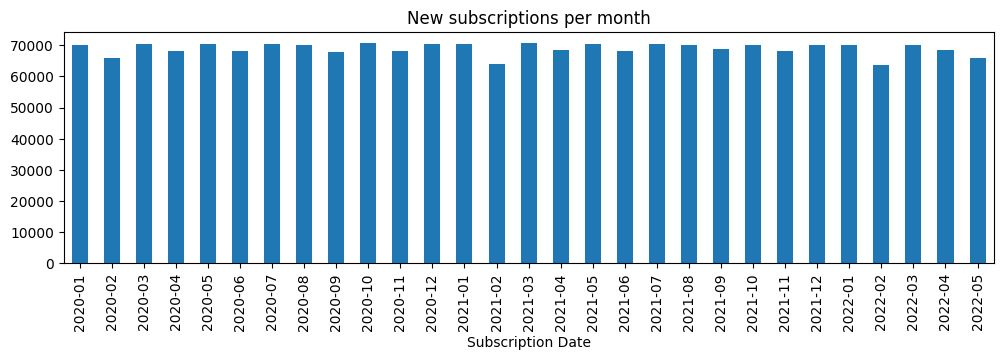

In [11]:
with track("subscription date"):
    monthly, weekday = None, None
    first, last, invalid = None, None, 0
    for chunk in read_chunks(["Subscription Date"]):
        sub = pd.to_datetime(chunk["Subscription Date"], errors="coerce")
        invalid += sub.isna().sum()
        monthly = add_counts(monthly, sub.dt.to_period("M").value_counts())
        weekday = add_counts(weekday, sub.dt.day_name().value_counts())
        first = sub.min() if first is None else min(first, sub.min())
        last = sub.max() if last is None else max(last, sub.max())

print("Range:", first.date(), "->", last.date(), "| invalid dates:", invalid)
print("------------------------")
monthly = monthly.astype(int).sort_index()   # chronological order
display(monthly)
monthly.plot(kind="bar", figsize=(12, 3), title="New subscriptions per month")
print("------------------------")
display(weekday.astype(int).sort_values(ascending=False))

Subscriptions run from 2020-01-01 to 2022-05-30. New subscriptions per month stay between 63,671 and 70,780 with no clear trend (the lowest months are February, which has fewer days), and every day of the week has between 283,817 and 287,309 subscriptions in total.

## Email & Website

In [12]:
with track("email & website"):
    email_domain, tld = None, None
    for chunk in read_chunks(["Email", "Website"]):
        email_domain = add_counts(email_domain, chunk["Email"].str.split("@").str[1].str.lower().value_counts())
        tld = add_counts(tld, chunk["Website"].str.extract(r"\.([a-z]+)/?$", expand=False).value_counts())

email_domain = email_domain.astype(int).sort_values(ascending=False)
print("Unique email domains:", email_domain.size)
print("------------------------")
display(email_domain.head(10))
print("------------------------")
display((tld / tld.sum() * 100).round(1).sort_values(ascending=False))

[email & website] peak memory: 116.4 MB | time: 73.65 seconds
Unique email domains: 592802
------------------------


Email
rojas.com        898
benson.com       889
huang.com        886
valentine.com    873
schmidt.com      870
barrera.com      869
wolfe.com        869
tapia.com        867
huynh.com        867
fry.com          865
Name: count, dtype: int64

------------------------


Website
com     60.0
biz     10.0
info    10.0
net     10.0
org     10.0
Name: count, dtype: float64

Emails come from 592,802 different domains and none of them is dominant (the most common, rojas.com, has only 898 customers). Website domains are split exactly like in the 100k file: 60% '.com' and 10% each for '.biz', '.info', '.net' and '.org'.

## Chunk Size

Here I try different chunk sizes to see how they change the memory and the time. To make it fair, every run only counts the rows, so most of the time is used for reading the file.

In [13]:
# Function to read the whole file with a given chunk size, it only counts the rows
def count_rows(chunk_size):
    n = 0
    for chunk in pd.read_csv(PATH, chunksize=chunk_size):
        n += len(chunk)
    return n

experiment = []
for size in [10_000, 50_000, 200_000, 500_000]:
    # Run 2 times: first for the peak memory, second for the time (tracemalloc makes it slower)
    tracemalloc.start()
    count_rows(size)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    start_time = time.time()
    count_rows(size)
    end_duration = time.time() - start_time

    experiment.append({
        "chunk_size": size,
        "n_chunks": n_rows // size,
        "peak_mb": round(peak / 1e6, 1),
        "time_s": round(end_duration, 2),
    })
    print("Chunk size", size, "done")

experiment = pd.DataFrame(experiment)
print("------------------------")
display(experiment)

Chunk size 10000 done


Chunk size 50000 done


Chunk size 200000 done


Chunk size 500000 done
------------------------


,chunk_size,n_chunks,peak_mb,time_s
0,10000,200,11.8,11.36
1,50000,40,50.9,10.27
2,200000,10,198.8,10.20
3,500000,4,495.1,10.76


The peak memory grows together with the chunk size, around 1 MB for every 1.000 rows (12 MB for 10.000 rows, 495 MB for 500.000 rows). The time stays around 10 seconds for every chunk size. So for this file, a small chunk size like 50.000 is a good choice: the memory stays low and it is not slower.

## Category Data Type

Another way to lower the memory without chunks: columns with only a few unique values (Country 243, First Name 690, Last Name 1,000) can be saved as `category`. Pandas then keeps every unique text only once, and each row only keeps a small number that points to it.

In [14]:
# Load the whole file at once again, but with 'category' for the columns with few unique values
category_cols = {"Country": "category", "First Name": "category", "Last Name": "category"}

with track("read csv, category dtype (time only)", memory=False):
    df = pd.read_csv(PATH, dtype=category_cols)
del df

with track("read csv, category dtype"):
    df = pd.read_csv(PATH, dtype=category_cols)

print("------------------------")
print("DataFrame size after loading: ", round(df.memory_usage(deep=True).sum() / 1e6, 1), "MB")
del df

[read csv, category dtype (time only)] peak memory: None MB | time: 10.93 seconds


[read csv, category dtype] peak memory: 1264.6 MB | time: 21.73 seconds
------------------------


DataFrame size after loading:  1076.3 MB


With `category`, the DataFrame becomes smaller (1.076 MB instead of 1.403 MB). But the peak memory while reading is even higher (1.265 MB instead of 1.083 MB), because pandas reads those columns as text first and then converts them to `category`. So `category` helps to keep the data smaller after loading, but it does not solve the problem while reading. Chunking is still needed to keep the memory low.

In [15]:
# Save every measurement, to be compared with coding-1 in question number 3
df_results = pd.DataFrame(results)
df_results["file"] = "2M"
df_results.to_csv("results-2M.csv", index=False)
experiment.to_csv("chunk-size-experiment.csv", index=False)
display(df_results)

,label,peak_mb,time_s,file
0,read csv (time only),NaN,11.27,2M
1,read csv,1083.2,21.14,2M
2,overview,88.7,129.00,2M
3,read csv in chunks (time only),NaN,10.03,2M
4,read csv in chunks,50.9,23.06,2M
5,country (time only),NaN,3.36,2M
6,data quality,69.9,97.25,2M
7,duplicate emails,101.6,26.23,2M
8,country,3.8,3.45,2M
9,phone patterns,74.2,62.70,2M


## Conclusion

1. **The large file can be parsed with low memory.** Reading it in chunks of 50,000 rows and keeping only aggregates, every section peaked between 4 MB and 151 MB, while loading the whole file at once peaked at 1,083 MB. Reading the file in chunks takes the same time as loading it at once (around 10 seconds). The trade-off is that each section reads the file again, so all the analysis sections together take about 8 minutes.
2. **The data is complete.** There are no missing values, no duplicate rows and no duplicate Customer IDs.
3. **Email is not a unique identifier.** 1,249 email addresses are shared by 2,499 customers in different countries.
4. **Customers are spread evenly across 243 countries** (about 8,230 each); Korea and Congo have about double, likely because each name covers two countries.
5. **Phone numbers use 21 formats, 60% have an extension, and the only country code is '+1'**, at the same rate in every country, so they do not reflect the customer's country.
6. **Subscriptions show no trend** between January 2020 and May 2022, and are almost equal on every day of the week.
7. **The 2M file shows the same patterns as the 100k file.** All shares (60% extensions, 16% '+1', 60% '.com', the doubled Korea and Congo) are the same, which confirms that the data is **synthetic (randomly generated)**.